# IEEE 33 bus : reseau de distribution radial

Reseau de distribution radial **IEEE 33 bus** (Baran et Wu, 1989), 12,66 kV,
3,7 MW de charge repartie sur 32 bus. Le poste source est un **bus infini** au
bus 1. Les lignes n'ont pas de capacite : tous les noeuds sont algebriques,
avec leur resistance de causalite de 100 pu, et la dynamique ne vient que des
branches et des charges.

```
  IB - 1 - 2 - 3 - 4 - 5 - 6 - 7 - ... - 18
           |   |           \
          19  23           26 - 27 - ... - 33
          ... ...
```

Base systeme : **10 MVA, 60 Hz**.

Equivalent MATLAB : `matlab/G2Elin_V2/reseaux_test/reseaux_classiques/IEEE33.m`.

**Impedances.** Les R, X des lignes sont ceux de Baran et Wu, en ohm
(0,0922 + j0,0470 ohm pour la ligne 1-2), soit `case33bw` de MATPOWER, divises
par la base 12,66 kV / 10 MVA (16,03 ohm). Jusqu'au 2026-10-25 le notebook
portait des valeurs 1,157 fois trop petites (FR-021) ; `IEEE33.m` les garde
encore.

### Comment comparer avec MATLAB

| Notebook (Python) | MATLAB |
|---|---|
| `net.run_loadflow()` | `net.Load_flow(Y_DER, false)` |
| `net.build_state_space()` | `net.buildGlobalModel()` |
| tableau modal ci-dessous | `displayModalAnalysis()` (`EigenVal_Table = 1`) |

Le tableau modal reprend les conventions MATLAB : participation
`p_ki = |v_gauche . v_droit|` normalisee par mode, `f_undamp = |lambda|/2pi`,
`f_damp = |Im(lambda)|/2pi`, `zeta = -Re(lambda)/|lambda|`, tri par
`Re(lambda)` decroissant, tous les modes conjugues inclus.

In [1]:
import sys
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import plotly.graph_objects as go


# Le paquet g2egrid est a la racine du projet (dossier parent de reseaux_test/).
ROOT = pathlib.Path.cwd()
ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from g2egrid import Network  # noqa: E402
from g2egrid.elements import (  # noqa: E402
    GFL1,
    GFL2,
    GFM1,
    GFM2,
    GFM3,
    GFM4,
    IB,
    Bus,
    ILoad,
    Line,
    PLoad,
    RLLoad,
    SynchronousMachine,
    SynchronousMachineTR,
    Transformer,
)

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

## 1. Construction du reseau

### 1.1 Donnees et assemblage

In [2]:
NOM_RESEAU = "IEEE33"
F_ZOOM = 5.0

f0 = 60.0
Sb = 10e6

Ub = 12.66e3
ZB = Ub**2 / 10e6  # base d'impedance des lignes [ohm] : les R, X de
# T_Lines_pu sont ceux de Baran et Wu en ohm (= case33bw de MATPOWER) / ZB

# BusType : 1 = slack, 2 = PV, 3 = PQ

Y_DER = [ # [BusID, BusType, V_base, V_pu, Theta_rad,   Pg_W, Qg_var,     Pl_W,   Ql_var]
        ( 1, 1, Ub, 1.000, 0, 0, 0,     0,     0),
        ( 2, 3, Ub, 1.000, 0, 0, 0, 100e3,  60e3),
        ( 3, 3, Ub, 1.000, 0, 0, 0,  90e3,  40e3),
        ( 4, 3, Ub, 1.000, 0, 0, 0, 120e3,  80e3),
        ( 5, 3, Ub, 1.000, 0, 0, 0,  60e3,  30e3),
        ( 6, 3, Ub, 1.000, 0, 0, 0,  60e3,  20e3),
        ( 7, 3, Ub, 1.000, 0, 0, 0, 200e3, 100e3),
        ( 8, 3, Ub, 1.000, 0, 0, 0, 200e3, 100e3),
        ( 9, 3, Ub, 1.000, 0, 0, 0,  60e3,  20e3),
        (10, 3, Ub, 1.000, 0, 0, 0,  60e3,  20e3),
        (11, 3, Ub, 1.000, 0, 0, 0,  45e3,  30e3),
        (12, 3, Ub, 1.000, 0, 0, 0,  60e3,  35e3),
        (13, 3, Ub, 1.000, 0, 0, 0,  60e3,  35e3),
        (14, 3, Ub, 1.000, 0, 0, 0, 120e3,  80e3),
        (15, 3, Ub, 1.000, 0, 0, 0,  60e3,  10e3),
        (16, 3, Ub, 1.000, 0, 0, 0,  60e3,  20e3),
        (17, 3, Ub, 1.000, 0, 0, 0,  60e3,  20e3),
        (18, 3, Ub, 1.000, 0, 0, 0,  90e3,  40e3),
        (19, 3, Ub, 1.000, 0, 0, 0,  90e3,  40e3),
        (20, 3, Ub, 1.000, 0, 0, 0,  90e3,  40e3),
        (21, 3, Ub, 1.000, 0, 0, 0,  90e3,  40e3),
        (22, 3, Ub, 1.000, 0, 0, 0,  90e3,  40e3),
        (23, 3, Ub, 1.000, 0, 0, 0,  90e3,  50e3),
        (24, 3, Ub, 1.000, 0, 0, 0, 420e3, 200e3),
        (25, 3, Ub, 1.000, 0, 0, 0, 420e3, 200e3),
        (26, 3, Ub, 1.000, 0, 0, 0,  60e3,  25e3),
        (27, 3, Ub, 1.000, 0, 0, 0,  60e3,  25e3),
        (28, 3, Ub, 1.000, 0, 0, 0,  60e3,  20e3),
        (29, 3, Ub, 1.000, 0, 0, 0, 120e3,  70e3),
        (30, 3, Ub, 1.000, 0, 0, 0, 200e3, 600e3),
        (31, 3, Ub, 1.000, 0, 0, 0, 150e3,  70e3),
        (32, 3, Ub, 1.000, 0, 0, 0, 210e3, 100e3),
        (33, 3, Ub, 1.000, 0, 0, 0,  60e3,  40e3),
]

# T_Lines_SI : [ID, From, To, Length_km, R_ohm/km, X_ohm/km, B_S/km]
T_Lines_SI = []

# T_Lines_pu : [ID, From, To, Length_km, R_pu, X_pu, B_pu, Un_V, Sb_VA]
#   R_pu, X_pu, B_pu : valeurs TOTALES de la ligne, en pu sur (Un_V, Sb_VA)
T_Lines_pu = [
    ( 1,  1,  2, 1, 0.0922/ZB,  0.047/ZB, 0.0, Ub, 10e6),
    ( 2,  2,  3, 1,  0.493/ZB, 0.2511/ZB, 0.0, Ub, 10e6),
    ( 3,  3,  4, 1,  0.366/ZB, 0.1864/ZB, 0.0, Ub, 10e6),
    ( 4,  4,  5, 1, 0.3811/ZB, 0.1941/ZB, 0.0, Ub, 10e6),
    ( 5,  5,  6, 1,  0.819/ZB,  0.707/ZB, 0.0, Ub, 10e6),
    ( 6,  6,  7, 1, 0.1872/ZB, 0.6188/ZB, 0.0, Ub, 10e6),
    ( 7,  7,  8, 1, 0.7114/ZB, 0.2351/ZB, 0.0, Ub, 10e6),
    ( 8,  8,  9, 1,   1.03/ZB,   0.74/ZB, 0.0, Ub, 10e6),
    ( 9,  9, 10, 1,  1.044/ZB,   0.74/ZB, 0.0, Ub, 10e6),
    (10, 10, 11, 1, 0.1966/ZB,  0.065/ZB, 0.0, Ub, 10e6),
    (11, 11, 12, 1, 0.3744/ZB, 0.1238/ZB, 0.0, Ub, 10e6),
    (12, 12, 13, 1,  1.468/ZB,  1.155/ZB, 0.0, Ub, 10e6),
    (13, 13, 14, 1, 0.5416/ZB, 0.7129/ZB, 0.0, Ub, 10e6),
    (14, 14, 15, 1,  0.591/ZB,  0.526/ZB, 0.0, Ub, 10e6),
    (15, 15, 16, 1, 0.7463/ZB,  0.545/ZB, 0.0, Ub, 10e6),
    (16, 16, 17, 1,  1.289/ZB,  1.721/ZB, 0.0, Ub, 10e6),
    (17, 17, 18, 1,  0.732/ZB,  0.574/ZB, 0.0, Ub, 10e6),
    (18,  2, 19, 1,  0.164/ZB, 0.1565/ZB, 0.0, Ub, 10e6),
    (19, 19, 20, 1, 1.5042/ZB, 1.3554/ZB, 0.0, Ub, 10e6),
    (20, 20, 21, 1, 0.4095/ZB, 0.4784/ZB, 0.0, Ub, 10e6),
    (21, 21, 22, 1, 0.7089/ZB, 0.9373/ZB, 0.0, Ub, 10e6),
    (22,  3, 23, 1, 0.4512/ZB, 0.3083/ZB, 0.0, Ub, 10e6),
    (23, 23, 24, 1,  0.898/ZB, 0.7091/ZB, 0.0, Ub, 10e6),
    (24, 24, 25, 1,  0.896/ZB, 0.7011/ZB, 0.0, Ub, 10e6),
    (25,  6, 26, 1,  0.203/ZB, 0.1034/ZB, 0.0, Ub, 10e6),
    (26, 26, 27, 1, 0.2842/ZB, 0.1447/ZB, 0.0, Ub, 10e6),
    (27, 27, 28, 1,  1.059/ZB, 0.9337/ZB, 0.0, Ub, 10e6),
    (28, 28, 29, 1, 0.8042/ZB, 0.7006/ZB, 0.0, Ub, 10e6),
    (29, 29, 30, 1, 0.5075/ZB, 0.2585/ZB, 0.0, Ub, 10e6),
    (30, 30, 31, 1, 0.9744/ZB,  0.963/ZB, 0.0, Ub, 10e6),
    (31, 31, 32, 1, 0.3105/ZB, 0.3619/ZB, 0.0, Ub, 10e6),
    (32, 32, 33, 1,  0.341/ZB, 0.5302/ZB, 0.0, Ub, 10e6),
]

# T_Shunts : [ID, BusID, B_pu]   (compensation shunt propre au bus)
T_Shunts = []

# T_Transfos : [ID, From, To, Sn_VA, U1_V, U2_V, R_pu, X_pu]
T_Transfos = []

# T_IBs : [ID, BusID, Sn_VA, E_pu, theta_deg, R_pu, X_pu]
T_IBs = [
    (1, 1, 100e6, 1.00, 0, 0.001, 0.01),
]

# T_SMs : [ID, BusID, Sn_VA]  ou  [ID, BusID, Sn_VA, Rt_pu, Xt_pu]
T_SMs = []

# T_GFM1s a T_GFM4s : [ID, BusID, Sn_VA, Vdc_V]  ou  [ID, BusID, Sn_VA, Vdc_V, Rt_pu, Xt_pu]
T_GFM1s = []
T_GFM2s = []
T_GFM3s = []
T_GFM4s = []

# T_GFL1s, T_GFL2s : [ID, BusID, Sn_VA, Vdc_V]  ou  [ID, BusID, Sn_VA, Vdc_V, Rt_pu, Xt_pu]
T_GFL1s = []
T_GFL2s = []

# T_Loads : [ID, BusID, P_W, Q_var, Type]   (charges SPECIALES)
#   Type : 'I' = courant constant, 'P' = puissance constante. Les charges
#   classiques (R-L) viennent des colonnes Pl_W, Ql_var de Y_DER ; une charge
#   speciale s'y ajoute, load flow compris. Exemple : (1, 7, 0.5e6, 0.1e6, 'P'),
T_Loads = []

In [3]:
# --- bases de tension par bus, lues dans Y_DER ---
UN = {int(r[0]): r[2] for r in Y_DER}

# --- capacite shunt de chaque bus : moitie de la charge des lignes qui y
#     aboutissent (schema en pi), comme C_half = B_pu/2 dans Network.m. Un bus
#     qui n'en recoit aucune devient un noeud ALGEBRIQUE a resistance de
#     causalite R = 100 pu (Node.m / setResistor(100)). ---
Cbus = {int(r[0]): 0.0 for r in Y_DER}
for _id, i, j, km, _r, _x, b_km in T_Lines_SI:
    b_pu = b_km * km * (UN[i] ** 2 / Sb)
    Cbus[i] += b_pu / 2.0
    Cbus[j] += b_pu / 2.0
for _id, i, j, _km, _r, _x, b_pu, Un, Sb_l in T_Lines_pu:
    b_pu = b_pu * (UN[i] ** 2 / Sb) / (Un ** 2 / Sb_l)  # base de la ligne -> base systeme
    Cbus[i] += b_pu / 2.0
    Cbus[j] += b_pu / 2.0
# compensation shunt propre a un bus (banc de condensateurs), qui s'ajoute a
# la charge capacitive des lignes. MATLAB n'a pas de colonne pour cela dans
# Y_DER : d'ou une table a part, plutot qu'une colonne en plus.
for _id, b, B_pu in T_Shunts:
    Cbus[b] += B_pu

# --- charges speciales de T_Loads : leur consommation s'ajoute a celle de
#     Y_DER dans le load flow ---
CHARGES_SPECIALES = {"I": ILoad, "P": PLoad}
S_spec = {int(r[0]): [0.0, 0.0] for r in Y_DER}
for _id, b, P, Q, typ in T_Loads:
    if typ not in CHARGES_SPECIALES:
        raise ValueError(f"T_Loads, charge {_id} : type '{typ}' inconnu ('I' ou 'P')")
    S_spec[b][0] += P
    S_spec[b][1] += Q

# --- assemblage du reseau
net = Network(f0=f0, Sb=Sb)

for bid, btype, Un, Vpu, theta, Pg, Qg, Pl, Ql in Y_DER:  # Y_DER
    net.add(
        Bus(
            int(bid),
            Un,
            btype=int(btype),
            V=Vpu,
            theta=theta,
            Pg=Pg,
            Qg=Qg,
            Pl=Pl + S_spec[int(bid)][0],
            Ql=Ql + S_spec[int(bid)][1],
            C=Cbus[int(bid)],
        )
    )

for lid, i, j, km, r_km, x_km, _b in T_Lines_SI:  # T_Lines_SI
    ZB = UN[i] ** 2 / Sb
    net.add(
        Line(
            f"L{int(lid)}_{i}_{j}", i, j, R=r_km * km / ZB, X=x_km * km / ZB, wb=net.wb
        )
    )

for lid, i, j, _km, r_pu, x_pu, _b, Un, Sb_l in T_Lines_pu:  # T_Lines_pu
    k = (Un ** 2 / Sb_l) / (UN[i] ** 2 / Sb)  # base de la ligne -> base systeme
    net.add(Line(f"L{int(lid)}_{i}_{j}", i, j, R=r_pu * k, X=x_pu * k, wb=net.wb))

# Une prise hors nominal se declare par U1_V/U2_V, comme dans Network.m :
# n = (U1/U2)/(Un_i/Un_j), egal a 1 quand U1, U2 sont les tensions des bus.
for tid, i, j, Sn, U1, U2, R, X in T_Transfos:  # T_Transfos
    k = (Sb / Sn) * (U1 / UN[i]) ** 2  # base du transfo -> base systeme
    n = (U1 / U2) / (UN[i] / UN[j])
    net.add(Transformer(f"T{int(tid)}_{i}_{j}", i, j, R=R * k, X=X * k, wb=net.wb, n=n))

for _id, b, Sn, _E, _th, R, X in T_IBs:  # T_IBs
    net.add(IB(f"IB{b}", b, R=R, X=X, wb=net.wb, Sn=Sn, Sb=Sb))

# Colonnes optionnelles Rt_pu, Xt_pu des tables de DER : transfo de
# raccordement INTEGRE a l'equipement. Sans elles, la machine n'a pas de
# transfo (a declarer dans T_Transfos) et le convertisseur garde son filtre
# R2/L2 par defaut.
for _id, b, Sn, *Tr in T_SMs:  # T_SMs
    if Tr:
        net.add(SynchronousMachineTR(f"SM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, Rt=Tr[0], Lt=Tr[1], **SM_PARAMS))
    else:
        net.add(SynchronousMachine(f"SM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **SM_PARAMS))

for T_GFM, GFM in ((T_GFM1s, GFM1), (T_GFM2s, GFM2), (T_GFM3s, GFM3), (T_GFM4s, GFM4)):  # T_GFM1s a T_GFM4s
    for _id, b, Sn, _Vdc, *Tr in T_GFM:
        tr = dict(R2_pu=Tr[0], L2_pu=Tr[1]) if Tr else {}
        net.add(GFM(f"GFM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **(GFM_PARAMS | tr)))

for T_GFL, GFL in ((T_GFL1s, GFL1), (T_GFL2s, GFL2)):  # T_GFL1s, T_GFL2s
    for _id, b, Sn, _Vdc, *Tr in T_GFL:
        tr = dict(R2_pu=Tr[0], L2_pu=Tr[1]) if Tr else {}
        net.add(GFL(f"GFL{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **(GFL_PARAMS | tr)))

# Charges classiques : colonnes Pl_W, Ql_var de Y_DER -> charge R-L a
# impedance constante (GenericLoad.m). Une inductance ne peut pas consommer
# un reactif negatif ou nul : condensateur dans T_Shunts, ou charge speciale.
n_rl = 0
for bid, *_, Pl, Ql in Y_DER:  # Y_DER : charges classiques
    if Pl == 0 and Ql == 0:
        continue
    if Ql <= 0:
        raise ValueError(
            f"bus {int(bid)} : Ql = {Ql:g} var. Une charge R-L demande Ql > 0 ; "
            "declarer le condensateur dans T_Shunts ou la charge dans T_Loads ('P' ou 'I')"
        )
    net.add(RLLoad(f"Load{int(bid)}", int(bid), P=Pl / Sb, Q=Ql / Sb, wb=net.wb))
    n_rl += 1

for lid, b, P, Q, typ in T_Loads:  # T_Loads : charges speciales
    net.add(CHARGES_SPECIALES[typ](f"Load{typ}{int(lid)}_{b}", b, P=P / Sb, Q=Q / Sb))

n_gfm = len(T_GFM1s) + len(T_GFM2s) + len(T_GFM3s) + len(T_GFM4s)
print(
    f"{NOM_RESEAU} : {len(Y_DER)} bus, "
    f"{len(T_Lines_SI) + len(T_Lines_pu)} ligne(s), {len(T_Transfos)} transfo(s), "
    f"{len(T_IBs)} bus infini, {len(T_SMs)} machine(s), {n_gfm} GFM, "
    f"{len(T_GFL1s) + len(T_GFL2s)} GFL, {n_rl} charge(s) R-L, "
    f"{len(T_Loads)} charge(s) speciale(s)"
)

IEEE33 : 33 bus, 32 ligne(s), 0 transfo(s), 1 bus infini, 0 machine(s), 0 GFM, 0 GFL, 32 charge(s) R-L, 0 charge(s) speciale(s)


### 1.2 Load flow

In [4]:
lf = net.run_loadflow()
print(
    f"Load flow : converge en {lf.iterations} iterations (mismatch {lf.mismatch:.2e})\n"
)

print(
    f"{'bus':>4} {'|V| [pu]':>10} {'angle [deg]':>12} "
    f"{'P inj [pu]':>12} {'Q inj [pu]':>12}"
)
print("-" * 54)
for b, i in net._bus_index().items():
    print(
        f"{b:>4} {abs(lf.V[i]):>10.4f} {np.degrees(np.angle(lf.V[i])):>12.4f} "
        f"{lf.S[i].real:>12.4f} {lf.S[i].imag:>12.4f}"
    )
print(
    f"\nSomme des injections : P = {lf.S.real.sum():+.4f} pu, "
    f"Q = {lf.S.imag.sum():+.4f} pu  (= pertes)"
)

Load flow : converge en 5 iterations (mismatch 4.94e-14)

 bus   |V| [pu]  angle [deg]   P inj [pu]   Q inj [pu]
------------------------------------------------------
   1     1.0000       0.0000       0.7021       0.2652
   2     0.9952      -0.0290      -0.0100      -0.0060
   3     0.9731      -0.1402      -0.0090      -0.0040
   4     0.9606      -0.1955      -0.0120      -0.0080
   5     0.9482      -0.2505      -0.0060      -0.0030
   6     0.9192      -0.8257      -0.0060      -0.0020
   7     0.9142      -1.3256      -0.0200      -0.0100
   8     0.9048      -1.3662      -0.0200      -0.0100
   9     0.8924      -1.6920      -0.0060      -0.0020
  10     0.8811      -1.9870      -0.0060      -0.0020
  11     0.8794      -1.9961      -0.0045      -0.0030
  12     0.8763      -2.0117      -0.0060      -0.0035
  13     0.8651      -2.3536      -0.0060      -0.0035
  14     0.8612      -2.5685      -0.0120      -0.0080
  15     0.8584      -2.6857      -0.0060      -0.0010
  16   

## 2. Modele d'etat

Equilibre element par element (Newton sur `[f; g] = 0`), puis assemblage
global : cablage des ports par LFT, elimination des variables algebriques
par complement de Schur.

In [5]:
net.solve_equilibrium()
ss = net.build_state_space()

print(ss)
print(f"\n{len(ss.states)} etats, {len(ss.inputs)} entrees, {len(ss.outputs)} sorties")
print(f"stable : {ss.is_stable()}   max Re(lambda) = {ss.eig().real.max():+.4e}")

print("\nEtats par element :")
seen = []
for s in ss.states:
    owner = s.split(".")[0]
    if owner not in seen:
        seen.append(owner)
for owner in seen:
    noms = [s.split(".", 1)[1] for s in ss.states if s.startswith(owner + ".")]
    print(f"  {owner:<12} {len(noms):>3} : {', '.join(noms)}")

<StateSpace 195 etats, 68 entrees, 232 sorties | max Re(lambda)=+0.000e+00>

195 etats, 68 entrees, 232 sorties


stable : True   max Re(lambda) = +0.0000e+00

Etats par element :
  L1_1_2         2 : i_d, i_q
  L2_2_3         2 : i_d, i_q
  L3_3_4         2 : i_d, i_q
  L4_4_5         2 : i_d, i_q
  L5_5_6         2 : i_d, i_q
  L6_6_7         2 : i_d, i_q
  L7_7_8         2 : i_d, i_q
  L8_8_9         2 : i_d, i_q
  L9_9_10        2 : i_d, i_q
  L10_10_11      2 : i_d, i_q
  L11_11_12      2 : i_d, i_q
  L12_12_13      2 : i_d, i_q
  L13_13_14      2 : i_d, i_q
  L14_14_15      2 : i_d, i_q
  L15_15_16      2 : i_d, i_q
  L16_16_17      2 : i_d, i_q
  L17_17_18      2 : i_d, i_q
  L18_2_19       2 : i_d, i_q
  L19_19_20      2 : i_d, i_q
  L20_20_21      2 : i_d, i_q
  L21_21_22      2 : i_d, i_q
  L22_3_23       2 : i_d, i_q
  L23_23_24      2 : i_d, i_q
  L24_24_25      2 : i_d, i_q
  L25_6_26       2 : i_d, i_q
  L26_26_27      2 : i_d, i_q
  L27_27_28      2 : i_d, i_q
  L28_28_29      2 : i_d, i_q
  L29_29_30      2 : i_d, i_q
  L30_30_31      2 : i_d, i_q
  L31_31_32      2 : i_d, i_q
  L3

### 2.1 Tableau modal

Une ligne par valeur propre, triee par partie reelle decroissante (modes les
plus lents d'abord), comme `displayModalAnalysis` en MATLAB : une paire
conjuguee occupe deux lignes. L'index `Mode` est l'indice `k` de `lam[k]`.

| Colonne | Definition |
|---|---|
| `Re`, `Im` | parties reelle [1/s] et imaginaire [rad/s] de la valeur propre |
| `f_und [Hz]` | frequence propre non amortie, `abs(lambda) / 2pi` |
| `f_dam [Hz]` | frequence d'oscillation, `abs(Im) / 2pi` |
| `zeta [%]` | amortissement, `-Re / abs(lambda)` |
| `Etat j`, `%j` | j-ieme etat le plus participant et sa participation `abs(v_ki . w_ik)`, normalisee a 100 % par mode |

In [6]:
lam, Vr = np.linalg.eig(ss.A)
Wl = np.linalg.inv(Vr)
Pf = np.abs(Vr.T) * np.abs(Wl)  # Pf[k, i] : participation de l'etat i au mode k
Pf = Pf / np.maximum(Pf.sum(axis=1, keepdims=True), 1e-30)
top3 = np.argsort(-Pf, axis=1)[:, :3]  # les trois etats les plus participants
k = np.arange(len(lam))

mag = np.abs(lam)
zeta = np.where(mag > 1e-10, -lam.real / np.where(mag > 1e-10, mag, 1.0), 0.0)

T_eig = pd.DataFrame(
    {
        "Re": lam.real,
        "Im": lam.imag,
        "f_und [Hz]": mag / (2 * np.pi),
        "f_dam [Hz]": np.abs(lam.imag) / (2 * np.pi),
        "zeta [%]": 100 * zeta,
    }
)
for j in range(3):
    T_eig[f"Etat {j + 1}"] = [ss.states[i] for i in top3[:, j]]
    T_eig[f"%{j + 1}"] = 100 * Pf[k, top3[:, j]]
T_eig = T_eig.iloc[np.argsort(-lam.real, kind="stable")]
T_eig.index.name = "Mode"



T_eig

,Re,Im,f_und [Hz],f_dam [Hz],zeta [%],Etat 1,%1,Etat 2,%2,Etat 3,%3
Mode,,,,,,,,,,,
130,0.000000e+00,0.000000,0.000000e+00,0.0,0.000000,IB1.theta,100.000000,L1_1_2.i_d,0.000000,L2_2_3.i_d,0.000000
68,-1.328495e+02,376.991118,6.361646e+01,60.0,33.236137,Load30.i_q,49.141035,Load30.i_d,49.141035,L27_27_28.i_d,0.227557
69,-1.328495e+02,-376.991118,6.361646e+01,60.0,33.236137,Load30.i_q,49.141035,Load30.i_d,49.141035,L27_27_28.i_d,0.227557
84,-5.645975e+02,376.991118,1.080488e+02,60.0,83.164706,Load14.i_q,44.778628,Load14.i_d,44.778628,Load11.i_d,3.108802
85,-5.645975e+02,-376.991118,1.080488e+02,60.0,83.164706,Load14.i_q,44.778628,Load14.i_d,44.778628,Load11.i_d,3.108802
...,...,...,...,...,...,...,...,...,...,...,...
5,-1.633089e+07,-376.991118,2.599143e+06,60.0,100.000000,L18_2_19.i_d,15.053346,L18_2_19.i_q,15.053346,IB1.i_d,11.876621
2,-2.254092e+07,376.991118,3.587499e+06,60.0,100.000000,L10_10_11.i_q,38.397524,L10_10_11.i_d,38.397524,L11_11_12.i_d,10.870866
3,-2.254092e+07,-376.991118,3.587499e+06,60.0,100.000000,L10_10_11.i_q,38.397524,L10_10_11.i_d,38.397524,L11_11_12.i_d,10.870866


### 2.2 Carte des valeurs propres

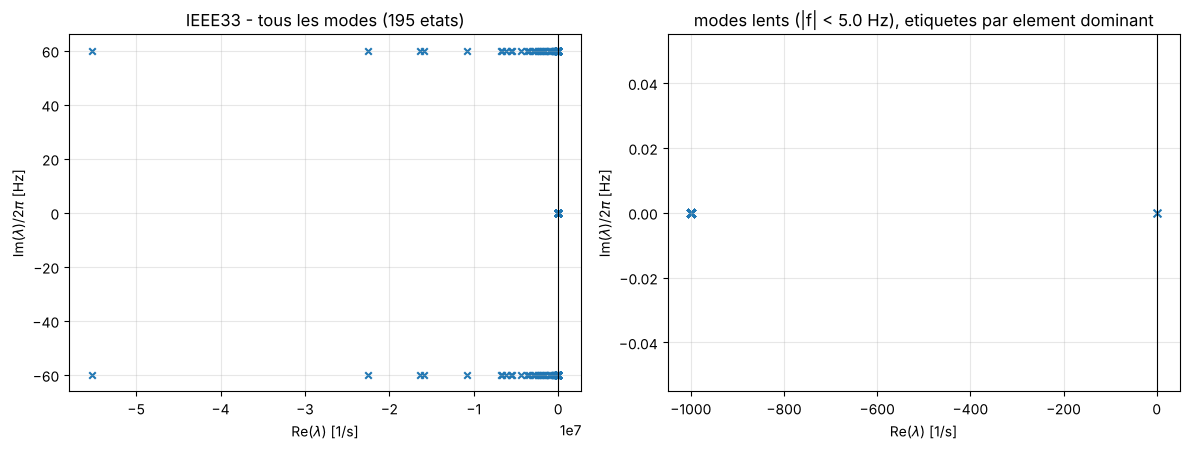

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))

ax[0].scatter(lam.real, lam.imag / (2 * np.pi), s=22, marker="x")
ax[0].axvline(0.0, color="k", lw=0.8)
ax[0].set_xlabel("Re($\\lambda$) [1/s]")
ax[0].set_ylabel("Im($\\lambda$)/2$\\pi$ [Hz]")
ax[0].set_title(f"{NOM_RESEAU} - tous les modes ({len(lam)} etats)")
ax[0].grid(True, alpha=0.3)

zoom = np.abs(lam.imag) / (2 * np.pi) <= F_ZOOM
ax[1].scatter(lam[zoom].real, lam[zoom].imag / (2 * np.pi), s=32, marker="x")
for k in np.flatnonzero(zoom & (lam.imag > 1e-6)):
    ax[1].annotate(
        ss.states[top3[k, 0]].split(".")[0],
        (lam[k].real, lam[k].imag / (2 * np.pi)),
        fontsize=7,
        xytext=(4, 3),
        textcoords="offset points",
    )
ax[1].axvline(0.0, color="k", lw=0.8)
ax[1].set_xlabel("Re($\\lambda$) [1/s]")
ax[1].set_ylabel("Im($\\lambda$)/2$\\pi$ [Hz]")
ax[1].set_title(f"modes lents (|f| < {F_ZOOM} Hz), etiquetes par element dominant")
ax[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

In [8]:
fig = go.Figure()

fig.add_trace(go.Scatter(x=T_eig["Re"], y=T_eig["Im"], mode="markers"))

fig.update_xaxes(range=[-1000, 10])
fig.update_yaxes(range=[-10, 1000])
fig.show()